# Jalon B — Chaîne signal : chirp → distance-Doppler → CFAR

Un radar de simulation est **un tableau complexe** `(N impulsions, n échantillons)` : le temps rapide (axe 1)
donne la distance, le temps lent (axe 0) donne la vitesse par effet Doppler. Chaîne :

1. **compression d'impulsion** (filtre adapté, FFT) sur le temps rapide : le chirp de 10 µs devient un pic
   de largeur ≈ 1/B, et le SNR est multiplié par T·fs ;
2. **FFT Doppler** fenêtrée sur le temps lent : le SNR est encore multiplié par ≈ N (moins la perte de la fenêtre) ;
3. **CA-CFAR 2D** : un seuil qui s'adapte au bruit local, pour garder une Pfa constante.

Les validations théoriques sont dans `tests/` (`test_waveform.py`, `test_simulate.py`, `test_processing.py`).
Ce notebook montre le résultat et trace la courbe **Pd en fonction du SNR**.

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import binomtest, ncx2

from radar.processing import (
    ca_cfar_2d, doppler_window, range_axis, range_doppler_map, velocity_axis,
)
from radar.simulate import Target, simulate_cpi
from radar.waveform import RadarParams

# --- style des figures : encre et surfaces neutres, rampe séquentielle bleue, catégories slots 1 et 2
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.8, "lines.solid_capstyle": "round", "font.family": "sans-serif",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
})
FIG_DIR = "../figures"

## Paramètres et scène

Bande X (λ ≈ 3,2 cm), B = 10 MHz, T = 10 µs, PRF = 1 kHz, N = 64 impulsions, fs = 2B.
Deux cibles **non ambiguës** en vitesse (|v| < λ·PRF/4 ≈ 8 m/s) : l'ambiguïté est traitée au jalon E.
Convention : v > 0 = la cible s'éloigne, ce qui donne une fréquence Doppler **négative** (−2v/λ).

In [2]:
P = RadarParams()
print(f"λ = {P.wavelength*100:.2f} cm | ΔR = {P.range_resolution:.1f} m | pas distance = {P.range_bin:.2f} m")
print(f"v_non_ambiguë = ±{P.unambiguous_velocity:.2f} m/s | Δv = {P.velocity_resolution:.3f} m/s | "
      f"gain compression T·fs = {P.compression_gain:.0f} ({10*np.log10(P.compression_gain):.1f} dB)")

PFA = 1e-4                       # probabilité de fausse alarme visée (par case)
SNR_DB = -15.0                   # SNR par échantillon d'une cible d'amplitude 1, avant tout traitement
TARGETS = [Target(3_000.0, 5.0, 1.0), Target(5_000.0, -6.0, 0.5)]

λ = 3.19 cm | ΔR = 15.0 m | pas distance = 7.50 m
v_non_ambiguë = ±7.98 m/s | Δv = 0.249 m/s | gain compression T·fs = 200 (23.0 dB)


## Figure 1 — Carte distance-Doppler et détections CFAR

La carte est en dB au-dessus du niveau de bruit (moyenne estimée par la médiane, qui vaut ln 2 fois la moyenne
pour un bruit exponentiel). Haut : carte entre 1 et 8 km. Bas : zoom autour de chaque cible.
Les deux échos sont invisibles dans le signal brut (SNR de −15 dB par échantillon), ils ressortent après les deux
intégrations. Les cercles isolés loin des cibles sont des **fausses alarmes** : avec Pfa = 10⁻⁴ sur 256 000 cases,
on en attend plusieurs dizaines par carte.

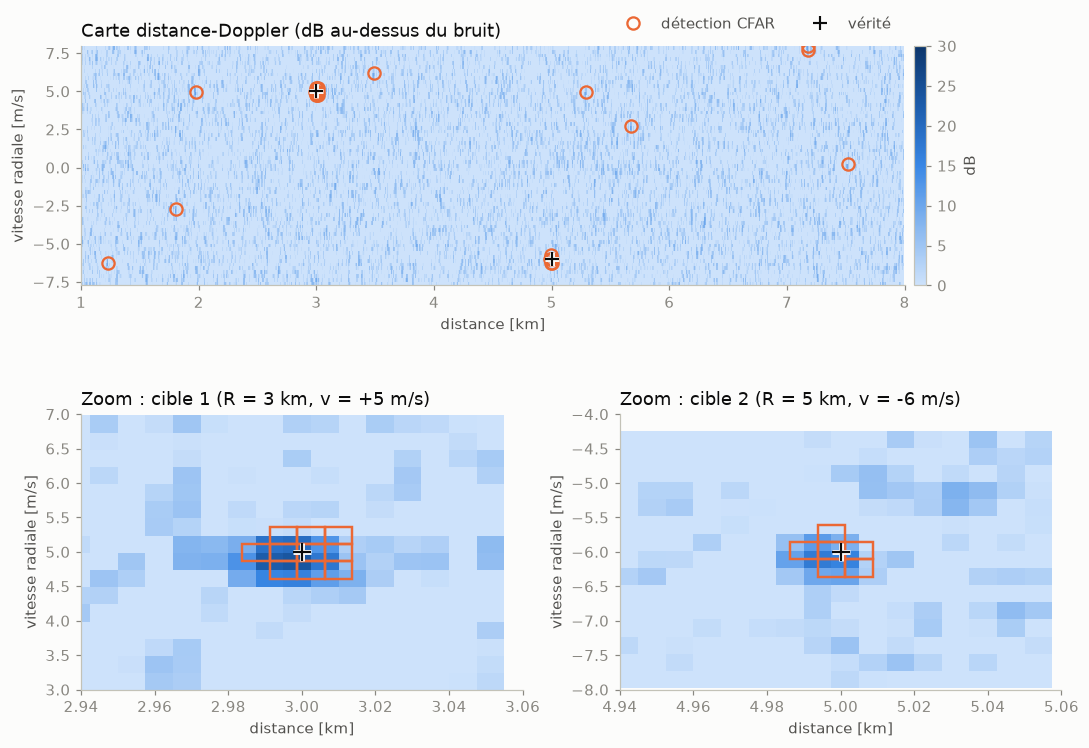

In [3]:
rx = simulate_cpi(P, TARGETS, snr_db=SNR_DB)
rd = range_doppler_map(rx, P)
power = np.abs(rd) ** 2
detections = ca_cfar_2d(power, PFA)

noise_mean = np.median(power) / np.log(2)
rd_db = 10 * np.log10(power / noise_mean)
R_ax, V_ax = range_axis(P), velocity_axis(P)
dv, dr = P.velocity_resolution, P.range_bin


def draw_map(ax, r_lo, r_hi, v_lo, v_hi, vmin, vmax, zoom):
    # Carte en dB sur une fenêtre (distance en km, vitesse en m/s) + détections CFAR + vérité.
    cols = (R_ax >= r_lo) & (R_ax <= r_hi)
    rows = (V_ax >= v_lo) & (V_ax <= v_hi)
    mesh = ax.pcolormesh(
        (R_ax[cols] - dr / 2) / 1e3, V_ax[rows] - dv / 2, rd_db[np.ix_(rows, cols)],
        cmap=SEQ_BLUE, vmin=vmin, vmax=vmax, shading="nearest", rasterized=True,
    )
    det_v, det_r = np.nonzero(detections[np.ix_(rows, cols)])
    for v, r in zip(V_ax[rows][det_v], R_ax[cols][det_r]):
        if zoom:   # contour de la case détectée
            ax.add_patch(plt.Rectangle(((r - dr / 2) / 1e3, v - dv / 2), dr / 1e3, dv, fill=False,
                                       ec=ORANGE, lw=1.6))
        else:      # anneau autour de la case (trop petite pour être contourée)
            ax.plot(r / 1e3, v, "o", ms=8, mfc="none", mec=ORANGE, mew=1.5)
    for tg in TARGETS:
        if r_lo <= tg.r0 <= r_hi and v_lo <= tg.v <= v_hi:
            ax.plot(tg.r0 / 1e3, tg.v, "+", ms=12 if zoom else 9, mec=SURFACE, mew=3.2)
            ax.plot(tg.r0 / 1e3, tg.v, "+", ms=12 if zoom else 9, mec=INK, mew=1.4)
    ax.set_xlim(r_lo / 1e3, r_hi / 1e3)
    ax.set_ylim(v_lo, v_hi)
    ax.grid(False)
    return mesh


fig = plt.figure(figsize=(11.5, 7.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.15], hspace=0.5, wspace=0.22)
ax_top = fig.add_subplot(gs[0, :])
mesh = draw_map(ax_top, 1_000, 8_000, V_ax.min(), V_ax.max(), 0, 30, zoom=False)
ax_top.set_xlabel("distance [km]")
ax_top.set_ylabel("vitesse radiale [m/s]")
ax_top.set_title("Carte distance-Doppler (dB au-dessus du bruit)", loc="left", color=INK)
fig.colorbar(mesh, ax=ax_top, pad=0.01, label="dB")

for k, tg in enumerate(TARGETS):
    ax = fig.add_subplot(gs[1, k])
    draw_map(ax, tg.r0 - 60, tg.r0 + 60, tg.v - 2.0, tg.v + 2.0, 0, 30, zoom=True)
    ax.set_xlabel("distance [km]")
    ax.set_ylabel("vitesse radiale [m/s]")
    ax.set_title(f"Zoom : cible {k+1} (R = {tg.r0/1e3:.0f} km, v = {tg.v:+.0f} m/s)", loc="left", color=INK)

# légende commune sous le titre de la carte (aucune détection n'est masquée)
handles = [
    plt.Line2D([], [], marker="o", ls="", ms=8, mfc="none", mec=ORANGE, mew=1.5, label="détection CFAR"),
    plt.Line2D([], [], marker="+", ls="", ms=9, mec=INK, mew=1.4, label="vérité"),
]
ax_top.legend(handles=handles, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, labelcolor=INK2)
fig.savefig(f"{FIG_DIR}/B_range_doppler.png", bbox_inches="tight")
plt.show()

### Validations chiffrées sur cette carte

Position du pic dans le voisinage de chaque cible, comparée à la vérité, et SNR de sortie mesuré comparé à la
prédiction `SNR_entrée × T·fs × (Σw)²/Σw²` (fenêtre de Hann). Le SNR mesuré est un peu plus bas que la prédiction
quand la cible tombe entre deux cases (perte de « straddle »).

In [4]:
w = doppler_window(P.n_pulses, "hann")
g_hann = w.sum() ** 2 / (w ** 2).sum()
print(f"gain Doppler (Hann) = {g_hann:.1f} (N = {P.n_pulses}, 2N/3 = {2*P.n_pulses/3:.1f})")
print(f"{'cible':>5s} {'R vrai':>8s} {'R pic':>8s} {'v vrai':>7s} {'v pic':>7s} {'SNR sortie mesuré':>18s} {'prédit (sur la case)':>21s}")
for k, tg in enumerate(TARGETS, 1):
    near_r = np.abs(R_ax - tg.r0) < 60
    sub = np.where(near_r[None, :], power, 0.0)
    i, j = np.unravel_index(np.argmax(sub), sub.shape)
    snr_in = tg.amplitude ** 2 * 10 ** (SNR_DB / 10)
    predicted = 10 * np.log10(snr_in * P.compression_gain * g_hann)
    measured = 10 * np.log10(power[i, j] / noise_mean)
    print(f"{k:5d} {tg.r0:8.1f} {R_ax[j]:8.1f} {tg.v:7.2f} {V_ax[i]:7.2f} {measured:15.1f} dB {predicted:18.1f} dB")

gain Doppler (Hann) = 42.0 (N = 64, 2N/3 = 42.7)
cible   R vrai    R pic  v vrai   v pic  SNR sortie mesuré  prédit (sur la case)
    1   3000.0   3002.5    5.00    4.99            23.8 dB               24.2 dB
    2   5000.0   4997.5   -6.00   -5.98            17.1 dB               18.2 dB


## Figure 2 — Pd en fonction du SNR (Pfa fixée)

200 tirages par SNR. À chaque tirage, une seule cible à une **position et une vitesse aléatoires** (continues, donc
pas calées sur les cases : la perte de straddle est incluse). Pd = fraction de tirages où le CFAR déclare au moins
une détection à ±1 case (distance et Doppler) de la case attendue. Barres : intervalle de Clopper-Pearson à 95 %.

Courbe théorique (bonus) : cible non fluctuante **calée sur une case**, bruit de référence connu, seuil
α = n·(Pfa^(−1/n) − 1) du CA-CFAR :
`Pd = P(χ'²₂(2·SNR_sortie) > 2α)`. Elle n'inclut ni la perte de straddle ni la fluctuation de l'estimation du bruit :
la courbe mesurée doit donc se placer **à droite** de la théorie.

In [5]:
N_DRAWS = 200
SNR_GRID = np.arange(-34.0, -21.5, 1.0)     # SNR par échantillon avant traitement [dB]
EXCL = 8                                    # on ignore ±8 cases autour de la cible pour compter les fausses alarmes


def one_draw(snr_db, rng):
    # Un tirage : cible aléatoire, simulation, chaîne complète. Retourne (détectée ?, fausses alarmes, cases testées).
    r0, v = rng.uniform(2_000, 8_000), rng.uniform(-6, 6)
    rx = simulate_cpi(P, [Target(r0, v, 1.0)], snr_db=snr_db, rng=rng)
    det = ca_cfar_2d(np.abs(range_doppler_map(rx, P)) ** 2, PFA)
    i = int(round(P.n_pulses / 2 - 2 * v / P.wavelength * P.n_pulses / P.prf))
    j = int(round((r0 - P.r_min) / P.range_bin))
    # axe Doppler circulaire (FFT) : indices modulo N ; axe distance borné : indices tronqués aux bords
    def window(half):
        rows = np.arange(i - half, i + half + 1) % P.n_pulses
        cols = np.arange(max(j - half, 0), min(j + half + 1, P.n_fast))
        return np.ix_(rows, cols)

    hit = det[window(1)].any()
    excluded = window(EXCL)
    outside = det.copy()
    outside[excluded] = False
    return hit, int(outside.sum()), det.size - excluded[0].size * excluded[1].size


rng = np.random.default_rng(P.seed)
hits = np.zeros(len(SNR_GRID), dtype=int)
false_alarms, cells_tested = 0, 0
for s, snr_db in enumerate(SNR_GRID):
    for _ in range(N_DRAWS):
        hit, fa, n_cells = one_draw(snr_db, rng)
        hits[s] += hit
        false_alarms += fa
        cells_tested += n_cells

pd_hat = hits / N_DRAWS
ci = np.array([binomtest(int(k), N_DRAWS).proportion_ci(0.95, "exact") for k in hits])
print(f"Pfa visée {PFA:.0e} | Pfa mesurée sur ces tirages : {false_alarms / cells_tested:.2e} "
      f"({false_alarms / cells_tested / PFA:.2f} × la visée, {false_alarms} fausses alarmes)")

Pfa visée 1e-04 | Pfa mesurée sur ces tirages : 1.67e-04 (1.67 × la visée, 110842 fausses alarmes)


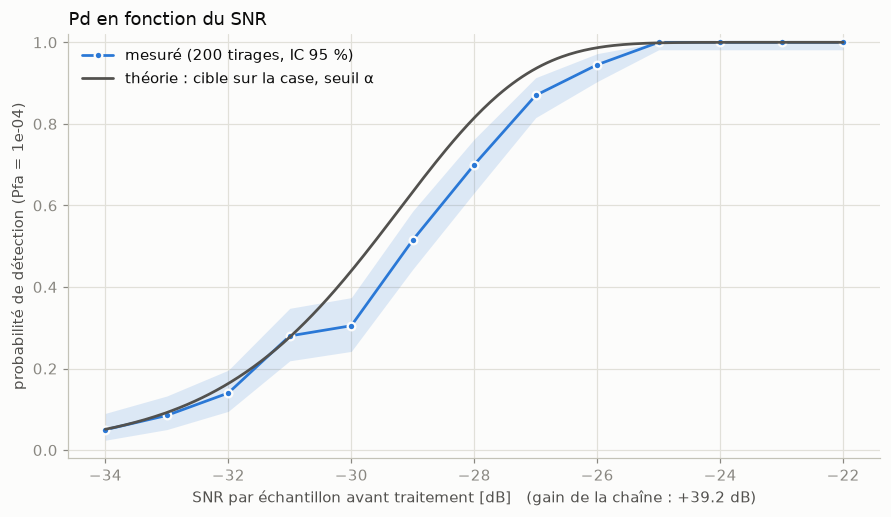

seuil de Pd = 0,5 : mesuré -29.1 dB, théorie -29.7 dB, écart +0.6 dB
seuil de Pd = 0,9 : mesuré -26.6 dB, théorie -27.4 dB, écart +0.8 dB
 SNR [dB]     Pd          IC 95 %
    -34.0  0.050   [0.024, 0.090]
    -33.0  0.085   [0.050, 0.133]
    -32.0  0.140   [0.095, 0.196]
    -31.0  0.280   [0.219, 0.348]
    -30.0  0.305   [0.242, 0.374]
    -29.0  0.515   [0.443, 0.586]
    -28.0  0.700   [0.631, 0.763]
    -27.0  0.870   [0.815, 0.913]
    -26.0  0.945   [0.904, 0.972]
    -25.0  1.000   [0.982, 1.000]
    -24.0  1.000   [0.982, 1.000]
    -23.0  1.000   [0.982, 1.000]
    -22.0  1.000   [0.982, 1.000]


In [6]:
# Courbe théorique : cible sur la case, seuil du CA-CFAR à n cellules de référence.
n_ref = (2 * (2 + 2) + 1) * (2 * (2 + 6) + 1) - (2 * 2 + 1) ** 2        # = 128 (fenêtre externe − garde)
alpha = n_ref * (PFA ** (-1.0 / n_ref) - 1.0)
gain_db = 10 * np.log10(P.compression_gain * g_hann)                      # gain total de la chaîne
snr_fine = np.linspace(SNR_GRID[0], SNR_GRID[-1], 300)
pd_theory = ncx2.sf(2 * alpha, df=2, nc=2 * 10 ** ((snr_fine + gain_db) / 10))


def snr_at(pd_target, snr, pd):
    # SNR d'entrée où la courbe croise pd_target (interpolation linéaire).
    return float(np.interp(pd_target, pd, snr))


fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.fill_between(SNR_GRID, ci[:, 0], ci[:, 1], color=BLUE, alpha=0.15, lw=0)
ax.plot(SNR_GRID, pd_hat, "o-", color=BLUE, ms=5, mec=SURFACE, mew=1.5,
        label=f"mesuré ({N_DRAWS} tirages, IC 95 %)")
ax.plot(snr_fine, pd_theory, color=INK2, label="théorie : cible sur la case, seuil α")
ax.set_xlabel(f"SNR par échantillon avant traitement [dB]   (gain de la chaîne : +{gain_db:.1f} dB)")
ax.set_ylabel(f"probabilité de détection (Pfa = {PFA:.0e})")
ax.set_ylim(-0.02, 1.02)
ax.set_title("Pd en fonction du SNR", loc="left", color=INK)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/B_pd_vs_snr.png")
plt.show()

meas50 = snr_at(0.5, SNR_GRID, pd_hat)
theo50 = snr_at(0.5, snr_fine, pd_theory)
meas90 = snr_at(0.9, SNR_GRID, pd_hat)
theo90 = snr_at(0.9, snr_fine, pd_theory)
print(f"seuil de Pd = 0,5 : mesuré {meas50:.1f} dB, théorie {theo50:.1f} dB, écart {meas50 - theo50:+.1f} dB")
print(f"seuil de Pd = 0,9 : mesuré {meas90:.1f} dB, théorie {theo90:.1f} dB, écart {meas90 - theo90:+.1f} dB")
print(f"{'SNR [dB]':>9s} {'Pd':>6s} {'IC 95 %':>16s}")
for snr_db, p, (lo, hi) in zip(SNR_GRID, pd_hat, ci):
    print(f"{snr_db:9.1f} {p:6.3f}   [{lo:5.3f}, {hi:5.3f}]")

## Ce qu'on retient

- Le pic tombe dans la bonne case distance et Doppler ; la vitesse lue est celle de la case Doppler
  (résolution Δv ≈ 0,25 m/s), avec le **signe** imposé par la phase `exp(−j2π·fc·τ)`.
- Les deux intégrations donnent ≈ +23 dB (compression, T·fs = 200) et ≈ +16 dB (Doppler, fenêtre de Hann) :
  une cible invisible dans le signal brut (−15 dB par échantillon) sort à ≈ 24 dB au-dessus du bruit.
- Le CA-CFAR tient sa Pfa à un facteur < 2 près (1,67 ×), mais **au-dessus** de la valeur visée. Explication la plus
  probable (non isolée par une expérience dédiée) : les cases voisines sont corrélées (compression sur-échantillonnée
  à fs = 2B, fenêtre de Hann), donc le bruit de référence est moins bien moyenné que si les n cellules étaient indépendantes.
- La courbe Pd(SNR) a la bonne forme (sigmoïde étroite) et se place à droite de la théorie, de ≈ 0,6 dB à Pd = 0,5
  et ≈ 0,8 dB à Pd = 0,9. Cet écart n'est pas décomposé entre perte de straddle (cible entre deux cases),
  fluctuation de l'estimation du bruit par le CFAR et corrélation des cellules.